# Forecasting a Nairobi Securities Exchange Stock: Safaricom and the Kenyan Economy

| Key              | Value |
|:-----------------|:------|
| **Course Codes** | BBT 4206 and BFS 4102 |
| **Course Names** | BBT 4206: Business Intelligence II (Week 7-9 of 13)<br>BFS 4102: Advanced Business Data Analytics (Week 1-3 of 13) |
| **Semester**     | September to December 2026 |
| **Lecturer**     | Allan Omondi |
| **Contact**      | aomondi@strathmore.edu |
| **Note**         | The lecture contains both theory and practice.<br/>This notebook forms part of the practice.<br/>It is intended for educational purposes only, and nothing in it is investment advice.<br/>Recommended citation: [BibTex](https://raw.githubusercontent.com/course-files/TimeSeriesForecastingandNeuralNetworks/refs/heads/main/RecommendedCitation.bib) |

## What you will learn in this notebook

By the end of this notebook you should be able to:

1. Find **free** market data for an African exchange, check where it comes from, and verify that a download is intact.
2. Clean raw exchange files that have inconsistent headings, mixed date formats, blank rows, stray rows, duplicates, and numbers stored as text.
3. Explain **thin trading** and **stale prices**, and why they change how you read a return.
4. Combine data that arrive at **different times of the day** and at **different frequencies** (daily prices, daily exchange rates, monthly inflation) without using information that nobody had at the time of the forecast.
5. Build predictors that describe the **Kenyan economy**: the banking sector, the rest of the market, the shilling, oil, global risk, and inflation.
6. Test honestly whether those predictors help to forecast the next-day return of **Safaricom**, using the same walk-forward protocol as Notebook 4.
7. Recognise a result that looks **too good**, find out where it comes from, and say what it does and does not show.

**Prerequisites:** Notebooks 1 to 4. In particular, you should be comfortable with returns, walk-forward validation, the naive forecast, and the Diebold-Mariano test.

**Run time:** about 2 to 3 minutes, plus a one-time download of about 20 MB the first time you run it.

## Why a Notebook About Kenya?

Notebooks 1 to 7 used Apple, a company traded in the largest and most heavily analysed market in the world. That choice was deliberate, because the data are clean and easy to obtain. It is not, however, the market that most of you will work in.

An analyst at a Nairobi bank, a pension scheme, or an asset manager faces a different situation. Compare the two settings:

| Question | A large US stock | A stock on the Nairobi Securities Exchange |
|:---------|:-----------------|:-------------------------------------------|
| How often does the stock trade? | Many times every second | Some shares trade every day, many do not |
| What is the price on a day without trades? | There is almost always a trade | The last price is carried forward (a **stale price**) |
| Where do I get the data? | One call to a free service | Free sources exist, but the files need **cleaning** |
| Are the prices adjusted for splits and dividends? | Yes, by the data provider | **Not** in the files we use |
| When does the market close, compared with the rest of the world? | The US markets close together | The NSE closes in the mid-afternoon, **before** Europe and the US |
| Which currency do I earn in? | US dollars | Kenya shillings (KES), and the shilling moves |
| How often is inflation published? | Monthly, with a delay | Monthly, with a delay |

None of these differences is a reason to stop. Each is a reason to be **more careful** with the steps you learned in the earlier notebooks. This notebook applies the same method (returns, walk-forward validation, the naive benchmark) to a Kenyan problem, and shows you where the Kenyan problem needs extra care.

The question is again:

> **Using only what we know at the close of today on the NSE, how well can we forecast Safaricom's closing price tomorrow, and does the extra information from the Kenyan economy beat simply saying "tomorrow will be the same as today"?**

## Step 1: Set Up the Notebook

In [1]:
import os
import sys
import subprocess

print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

# Google Colab starts with an empty workspace, so we fetch the lab files first.
# On your own computer this block does nothing.
if "google.colab" in sys.modules and not os.path.exists("tslab"):
    subprocess.run(["git", "clone", "https://github.com/course-files/TimeSeriesForecastingandNeuralNetworks.git"], check=True)
    os.chdir("TimeSeriesForecastingandNeuralNetworks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements/colab.txt"], check=True)
    print("Colab workspace prepared.")

Python interpreter: C:\Users\aomondi\Documents\GitHub\Teaching\TimeSeriesForecastingandNeuralNetworks\.venv\Scripts\python.exe
Python version    : 3.12.10


In [2]:
import re
import json
import time
import hashlib
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor

from tslab import config
from tslab.data import download_prices
from tslab.features import check_no_lookahead
from tslab.validation import walk_forward_splits, walk_forward_predict, describe_splits
from tslab.metrics import compare_models, diebold_mariano, dm_verdict, out_of_sample_r2
from tslab.plots import plot_walk_forward_layout, plot_price_forecasts, plot_acf_pacf

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

# ---- Settings you may change -------------------------------------------------
TARGET = "SCOM"                       # the NSE code of the stock we forecast (Safaricom)
FIRST_DATE = "2013-01-01"             # the NSE files start in January 2013
LAST_DATE = "2024-10-31"              # the free NSE files end here (see Step 2)
NSE_DIR = config.DATA_DIR / "nse"     # downloads are kept here, so that you download only once
NSE_DIR.mkdir(parents=True, exist_ok=True)

## Step 2: Where Can You Get Free Data?

This is the question that stops most projects, so we answer it first. For this notebook we use three free sources.

| What | Source | How often | Notes |
|:-----|:-------|:----------|:------|
| Daily prices and volumes of the NSE shares, and of the NSE indices, from January 2013 to October 2024 | **Mendeley Data**, datasets published by Barack Wanjawa of the University of Nairobi. DOIs: [10.17632/73rb78pmzw.2](https://doi.org/10.17632/73rb78pmzw.2) (2013 to 2020), [10.17632/97hkwn5y3x.4](https://doi.org/10.17632/97hkwn5y3x.4) (2021), [10.17632/jmcdmnyh2s.2](https://doi.org/10.17632/jmcdmnyh2s.2) (2022), [10.17632/ss5pfw8xnk.1](https://doi.org/10.17632/ss5pfw8xnk.1) (2023 to October 2024) | Daily | Free to download. The pages say that the data were collected from the MyStocks website, and they do not state a licence. |
| The Kenya shilling per US dollar, Brent crude oil, an emerging markets fund (EEM), and the VIX | **Yahoo Finance**, through the `yfinance` package | Daily | The same source as the earlier notebooks. |
| Kenya's consumer price index | **World Bank, Global Economic Monitor**, through the public World Bank API | Monthly | Collected from the national statistics office. |

Three remarks about these choices.

1. **We do not copy the NSE files into the course repository.** The Mendeley pages do not state a licence, so each student downloads the files directly from the publisher. The notebook checks every file against the checksum that Mendeley publishes, so that you know that the file is complete and unaltered. Checking a download in this way is good practice for any data you did not create yourself.
2. **Free does not mean authoritative.** The Mendeley files were collected by a researcher, not published by the exchange. For a serious project you would compare a sample of prices with the NSE's own daily price lists. The NSE sells historical data through its Data Services pages, which is a commercial product, so check the current terms on the NSE website.
3. **The free data stop in October 2024.** This is a limit of the source. If you need later dates, you can extend the data by hand, as explained in the exercises.

Other useful sources for the Kenyan economy are the **Central Bank of Kenya** (exchange rates, Treasury bill auction results, and the Central Bank Rate) and the **Kenya National Bureau of Statistics** (inflation). Their data are published as web pages, PDF files, and spreadsheets, so they need more work to collect, and we use them in the exercises.

### 2.1 Download the NSE files

The function below asks Mendeley for the list of files in each dataset, downloads the ones we need, and compares each file with the published SHA-256 checksum. If a file is already in `data/nse`, it is checked and not downloaded again.

If your internet connection blocks the download, open each DOI link in the table above in a browser, download the files whose names start with `NSE_data_all_stocks` and `NSE_data_stock_market_sectors`, and copy them to the `data/nse` folder. The rest of the notebook will work in the same way.

In [3]:
MENDELEY_DATASETS = {"73rb78pmzw": 2, "97hkwn5y3x": 4, "jmcdmnyh2s": 2, "ss5pfw8xnk": 1}   # dataset id: version


def fetch(url, timeout=120):
    """Download a URL and return the bytes."""
    request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (university course lab)"})
    with urllib.request.urlopen(request, timeout=timeout) as response:
        return response.read()


def download_nse_files(folder=NSE_DIR):
    """Download the NSE price files from Mendeley Data and verify each one against its checksum."""
    for dataset, version in MENDELEY_DATASETS.items():
        listing = json.loads(fetch(f"https://data.mendeley.com/public-api/datasets/{dataset}/files?folder_id=root&version={version}"))
        for item in listing:
            name = item["filename"]
            if not name.startswith(("NSE_data_all_stocks", "NSE_data_stock_market_sectors")):
                continue
            destination = folder / name
            expected = item["content_details"]["sha256_hash"]
            if destination.exists() and hashlib.sha256(destination.read_bytes()).hexdigest() == expected:
                continue
            content = fetch(item["content_details"]["download_url"])
            if hashlib.sha256(content).hexdigest() != expected:
                raise ValueError(f"{name} does not match its published checksum. Please try again.")
            destination.write_bytes(content)
            print("  downloaded and verified:", name)


try:
    download_nse_files()
except Exception as error:
    print("The automatic download did not work:", error)
    print("Download the files by hand (see the instructions above) and place them in", NSE_DIR)

price_files = sorted(NSE_DIR.glob("NSE_data_all_stocks_*.csv"))
print(f"{len(price_files)} price files are in {NSE_DIR}")
for path in price_files:
    print("  ", path.name)

  downloaded and verified: NSE_data_all_stocks_2013.csv
  downloaded and verified: NSE_data_all_stocks_2014.csv
  downloaded and verified: NSE_data_all_stocks_2015.csv
  downloaded and verified: NSE_data_all_stocks_2016.csv
  downloaded and verified: NSE_data_all_stocks_2017.csv
  downloaded and verified: NSE_data_all_stocks_2018.csv
  downloaded and verified: NSE_data_all_stocks_2019.csv
  downloaded and verified: NSE_data_all_stocks_2020.csv
  downloaded and verified: NSE_data_stock_market_sectors_2013.csv
  downloaded and verified: NSE_data_stock_market_sectors_2020.csv
  downloaded and verified: NSE_data_all_stocks_2021_upto_31dec2021.csv
  downloaded and verified: NSE_data_stock_market_sectors_as_at_31dec2021.csv
  downloaded and verified: NSE_data_all_stocks_2022.csv
  downloaded and verified: NSE_data_stock_market_sectors_2022.csv
  downloaded and verified: NSE_data_all_stocks_2023.csv
  downloaded and verified: NSE_data_all_stocks_2024_jan_to_oct.csv
  downloaded and verified: 

## Step 3: Read the Raw Files, and Meet the Problems

Raw data from a real source always contain surprises. Rather than hide them in a function, we find them one at a time. Each of the problems below is in the real files.

In [4]:
# Problem 1: the column headings are not the same in every file
headings = {}
for path in price_files:
    headings.setdefault(tuple(pd.read_csv(path, nrows=0).columns), []).append(path.name)
for heading, names in headings.items():
    print(f"{len(names):>2} file(s) use the headings {list(heading)}")
    print("     for example:", names[0])

 9 file(s) use the headings ['DATE', 'CODE', 'NAME', '12m Low', '12m High', 'Day Low', 'Day High', 'Day Price', 'Previous', 'Change', 'Change%', 'Volume', 'Adjust']
     for example: NSE_data_all_stocks_2013.csv
 3 file(s) use the headings ['Date', 'Code', 'Name', '12m Low', '12m High', 'Day Low', 'Day High', 'Day Price', 'Previous', 'Change', 'Change%', 'Volume', 'Adjusted Price']
     for example: NSE_data_all_stocks_2022.csv


In [5]:
# We read everything as text first, make the headings lower case, and stack the files
parts = []
for path in price_files:
    part = pd.read_csv(path, dtype=str)
    part.columns = [column.strip().lower() for column in part.columns]
    part["file"] = path.name
    parts.append(part)
raw = pd.concat(parts, ignore_index=True)
print("Rows read:", len(raw))

# Problem 2: blank rows
blank = raw["date"].isna() | raw["code"].isna()
print("\nRows without a date or a stock code:", int(blank.sum()))
raw = raw[~blank].copy()

# Problem 3: the date is written in more than one way
print("\nThe first date in each file shows the formats in use:")
print(raw.groupby("file")["date"].first().to_string())

Rows read: 201526

Rows without a date or a stock code: 2

The first date in each file shows the formats in use:
file
NSE_data_all_stocks_2013.csv                      2-Jan-13
NSE_data_all_stocks_2014.csv                     02-Jan-14
NSE_data_all_stocks_2015.csv                      2-Jan-15
NSE_data_all_stocks_2016.csv                     04-Jan-16
NSE_data_all_stocks_2017.csv                     03-Jan-17
NSE_data_all_stocks_2018.csv                     02-Jan-18
NSE_data_all_stocks_2019.csv                     02-Jan-19
NSE_data_all_stocks_2020.csv                     02-Jan-20
NSE_data_all_stocks_2021_upto_31dec2021.csv      04-Jan-21
NSE_data_all_stocks_2022.csv                      3-Jan-22
NSE_data_all_stocks_2023.csv                   03-Jan-2023
NSE_data_all_stocks_2024_jan_to_oct.csv         2-Jan-2024


In [6]:
raw["date"] = pd.to_datetime(raw["date"], format="mixed", dayfirst=True, errors="coerce")
print("Dates that could not be read:", int(raw["date"].isna().sum()))

# Problem 4: stray rows. A file named for one year should hold only dates from that year.
file_year = raw["file"].str.extract(r"(20\d\d)")[0].astype(int)
stray = raw["date"].dt.year != file_year
print("\nRows whose date is outside the year of the file:", int(stray.sum()))
print(raw.loc[stray, ["file", "date", "code"]].drop_duplicates(["file", "date"]).to_string(index=False))
raw = raw[~stray].copy()

Dates that could not be read: 0

Rows whose date is outside the year of the file: 70
                        file       date code
NSE_data_all_stocks_2017.csv 2015-05-09 EGAD


In [7]:
# Problem 5: numbers are stored as text ("4,000" with a comma, "-" for nothing, "8.24%" with a percent sign)
print("Examples of volume as text      :", raw["volume"].dropna().sample(6, random_state=1).tolist())
print("Examples of 'change %' as text  :", raw["change%"].dropna().sample(6, random_state=1).tolist())


def to_number(column):
    cleaned = column.astype(str).str.replace(",", "", regex=False).str.replace("%", "", regex=False).str.strip()
    return pd.to_numeric(cleaned.replace({"-": np.nan, "nan": np.nan, "": np.nan}), errors="coerce")


for column in ["day price", "day low", "day high", "previous", "volume"]:
    raw[column] = to_number(raw[column])

# Problem 6: the same stock appears twice on the same day
duplicates = raw.duplicated(["date", "code"], keep="first")
print("\nDuplicated (date, code) rows:", int(duplicates.sum()))
raw = raw[~duplicates].copy()
print("Rows after cleaning:", len(raw))

Examples of volume as text      : ['85,600', '1000', '30,600', '-', '6800', '100']
Examples of 'change %' as text  : ['-', '1.13%', '-', '-', '-', '3.39%']

Duplicated (date, code) rows: 69
Rows after cleaning: 201385


We now have one clean table. We reshape it into one table per measurement, with one column per stock. In the NSE files, **Day Price** is the last traded price of the day, so we treat it as the closing price.

In [8]:
close = raw.pivot(index="date", columns="code", values="day price").sort_index()
high = raw.pivot(index="date", columns="code", values="day high").sort_index()
low = raw.pivot(index="date", columns="code", values="day low").sort_index()
volume = raw.pivot(index="date", columns="code", values="volume").sort_index()

print("Trading days in the table:", len(close))
print("From", close.index.min().date(), "to", close.index.max().date())
print("Codes (stocks and indices):", close.shape[1])
print("Codes that are indices:", [c for c in close.columns if str(c).startswith("^")])

Trading days in the table: 2940
From 2013-01-02 to 2024-10-31
Codes (stocks and indices): 77
Codes that are indices: ['^FNK15', '^FNK25', '^N10I', '^N20I', '^N25I', '^NASI', '^NBDI', '^ZKEQTK', '^ZKEQTU']


## Step 4: Which Stocks Trade Often Enough to Forecast?

A forecast needs a series that **changes**. On the NSE, many stocks do not trade every day. We measure, for every stock:

- the share of days on which it **traded** (volume above zero),
- the share of days on which its price **did not change**, and
- its average **traded value** per day since it was listed (volume times price, in millions of shillings).

In [9]:
stocks = [c for c in close.columns if not str(c).startswith("^") and "-P" not in str(c)]

daily_return = np.log(close[stocks]).diff()
traded = volume[stocks].fillna(0) > 0
listing = pd.DataFrame({
    "first day": close[stocks].apply(lambda s: s.first_valid_index()).dt.date,
    "days listed": close[stocks].notna().sum(),
    "share of days traded": traded.sum() / close[stocks].notna().sum(),
    "share of days with an unchanged price": (daily_return == 0).sum() / daily_return.notna().sum(),
    "traded value per listed day (KES millions)": (close[stocks] * volume[stocks]).sum() / close[stocks].notna().sum() / 1e6,
})
listing = listing[listing["days listed"] > 500].sort_values("traded value per listed day (KES millions)", ascending=False)
listing.head(12).round(3)

,first day,days listed,share of days traded,share of days with an unchanged price,traded value per listed day (KES millions)
code,,,,,
SCOM,2013-01-02,2940,1.000,0.175,201.357
EQTY,2013-01-02,2940,1.000,0.207,93.594
KCB,2013-01-02,2940,1.000,0.202,75.923
EABL,2013-01-02,2940,0.997,0.169,59.329
KENO,2013-01-02,1686,0.903,0.301,20.098
BAT,2013-01-02,2940,0.838,0.343,18.870
COOP,2013-01-02,2940,1.000,0.222,13.153
ABSA,2013-01-02,2940,0.999,0.223,8.705
CTUM,2013-01-02,2940,1.000,0.106,8.603


In [10]:
print("Stocks listed for more than 500 days:", len(listing))
print("... of which traded on at least 90 percent of their days:", int((listing["share of days traded"] >= 0.9).sum()))
print("... of which traded on fewer than half of their days    :", int((listing["share of days traded"] < 0.5).sum()))

Stocks listed for more than 500 days: 65
... of which traded on at least 90 percent of their days: 33
... of which traded on fewer than half of their days    : 12


The ranking is by the average value traded per day. Safaricom is at the top, and it trades on almost every day, so it is the natural stock to forecast. A stock that trades on fewer than half of its days is a poor candidate for a daily forecast, and you will see why in Step 5.

**What the "unchanged price" column means.** When a stock does not trade, its quoted price stays at the last traded price, so its return is exactly zero. A return of zero then means "nothing happened" and not "the market valued the stock at the same price". Even for the most active stocks, many days show an unchanged price, partly because NSE prices move in small fixed steps.

## Step 5: Look at Safaricom

Before modelling, look at the series. We build the table for the target stock. If a price is missing on a day when the stock was listed, we use the previous price (this is the stale price convention), and we set the missing volume to zero.

In [11]:
frame = pd.DataFrame({
    "close": close[TARGET],
    "high": high[TARGET],
    "low": low[TARGET],
    "volume": volume[TARGET],
}).dropna(subset=["close"])
frame["high"] = frame["high"].fillna(frame["close"])
frame["low"] = frame["low"].fillna(frame["close"])
frame["volume"] = frame["volume"].fillna(0)
frame = frame.loc[FIRST_DATE:LAST_DATE]

r = np.log(frame["close"]).diff().dropna()
steps = frame["close"].diff().abs()
print(f"{TARGET}: {len(frame)} trading days, from {frame.index.min().date()} to {frame.index.max().date()}")
print(f"Share of days with an unchanged price: {(r == 0).mean():.1%}")
print(f"Smallest non-zero price step         : KES {steps[steps > 0].min():.2f}")
print(f"Largest one-day gain                 : {r.max():.1%} (log return)")
print(f"Largest one-day loss                 : {r.min():.1%} (log return)")
print(f"Days with a move larger than 8 percent: {(r.abs() > 0.08).sum()}")

SCOM: 2940 trading days, from 2013-01-02 to 2024-10-31
Share of days with an unchanged price: 17.5%
Smallest non-zero price step         : KES 0.05
Largest one-day gain                 : 9.7% (log return)
Largest one-day loss                 : -10.4% (log return)
Days with a move larger than 8 percent: 8


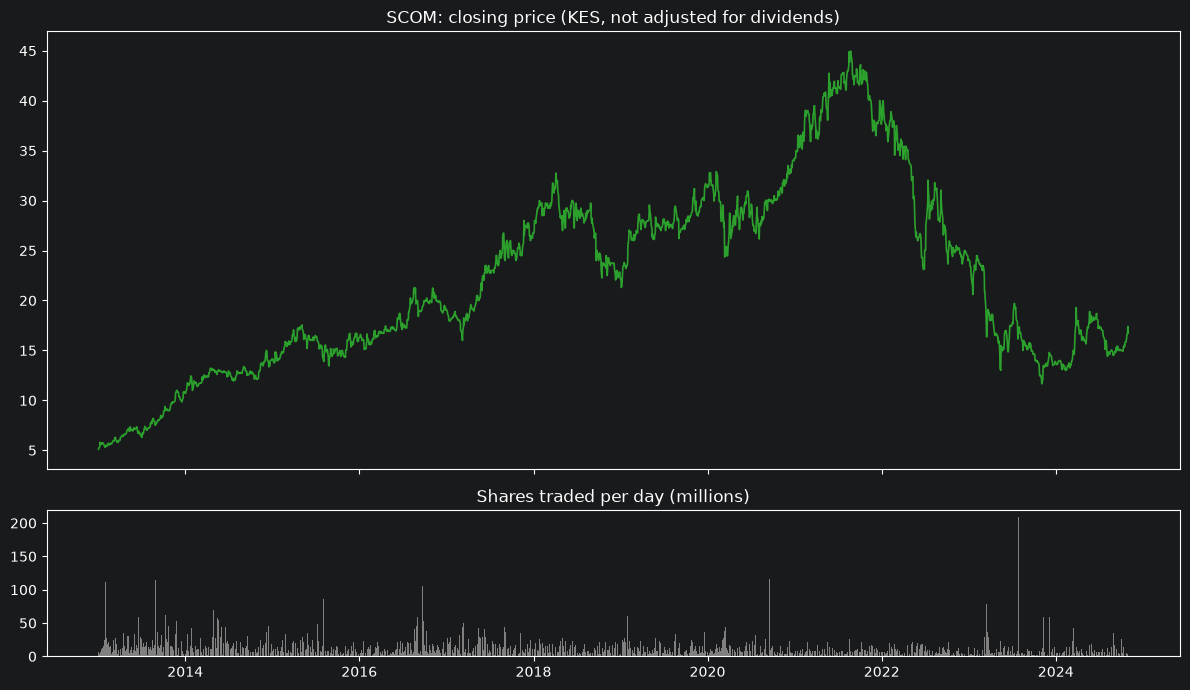

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
axes[0].plot(frame["close"], color="tab:green", linewidth=1.2)
axes[0].set_title(f"{TARGET}: closing price (KES, not adjusted for dividends)")
axes[1].bar(frame.index, frame["volume"] / 1e6, width=2, color="grey")
axes[1].set_title("Shares traded per day (millions)")
plt.tight_layout(); plt.show()

Three features of this series matter for what follows.

1. **The prices are not adjusted for dividends.** On the day a dividend is paid out of the company, the share price falls by about the amount of the dividend. The model sees an ordinary price fall. In the earlier notebooks, Yahoo Finance adjusted the prices to remove this effect. Here we forecast the **quoted price**, which is what an investor sees on the screen, and we keep the limitation in mind.
2. **A large share of returns is exactly zero**, because the price moves in steps and does not change on many days. Models that assume continuous returns are working with a simplification.
3. **The price fell sharply during the later part of the sample.** The shape of the chart is very different from a stock that rose for a decade. A forecasting method that worked in one period may not have worked in another.

### A first surprise: does yesterday's return help?

In Notebook 2 you tested whether yesterday's return of Apple helps to forecast today's return. The correlation was close to zero. Run the same check for Safaricom, for the whole sample and for each third of it, and for a few other actively traded NSE stocks.

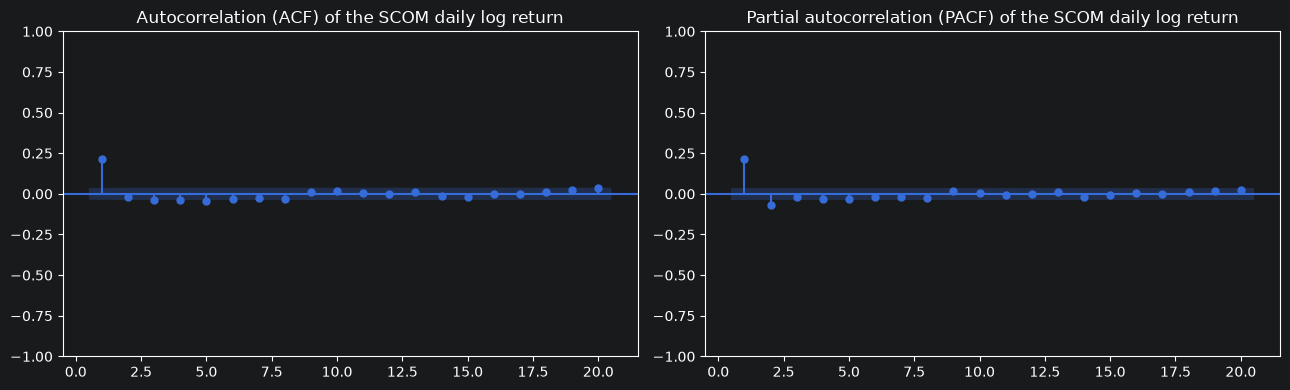

,Correlation of today's return with yesterday's
"SCOM, 2013 to 2016",0.238
"SCOM, 2017 to 2020",0.145
"SCOM, 2021 to 2024",0.244
"SCOM, all years",0.214
"EQTY, all years",0.214
"KCB, all years",0.264
"COOP, all years",0.163
"EABL, all years",0.059
"ABSA, all years",0.132
"BAT, all years",-0.137


In [13]:
plot_acf_pacf(r, lags=20, title=f"of the {TARGET} daily log return")

def lag1(series):
    return series.dropna().autocorr(1)

periods = {"2013 to 2016": ("2013", "2016"), "2017 to 2020": ("2017", "2020"), "2021 to 2024": ("2021", "2024")}
table = {f"{TARGET}, {name}": lag1(r.loc[a:b]) for name, (a, b) in periods.items()}
table[f"{TARGET}, all years"] = lag1(r)
for code_ in ["EQTY", "KCB", "COOP", "EABL", "ABSA", "BAT"]:
    table[f"{code_}, all years"] = lag1(np.log(close[code_].loc[FIRST_DATE:LAST_DATE]).diff())
pd.Series(table, name="Correlation of today's return with yesterday's").round(3).to_frame()

The correlation for Safaricom is about +0.2, and it is similar in each third of the sample. Several other active stocks show a positive value too. For Apple the value was close to zero. A correlation of this size is large for a share that trades every day, and it will shape everything that follows.

Several explanations are possible, and this data cannot separate them:

1. **Information is absorbed slowly.** In a market followed by few analysts, a piece of news may move the price over two or three days and not in one.
2. **Price limits.** If the exchange limits how far a price can move in a day, a large move can continue on the next day.
3. **How the "closing" price is built.** We do not know whether the *Day Price* in these files is the last trade of the day or an average over part of the day. An average of a random walk over a window is *positively* autocorrelated, by up to about 0.25, even when the underlying price has no predictability at all. A value of 0.2 is close to that figure. If this explanation is even partly true, the pattern is in the data, but it could not be earned by trading at the stated price.

Keep these three explanations in mind when you read the results in Step 10.

## Step 6: The Rest of the Market, Built From the Stock Prices

The first set of predictors comes from the NSE itself. Two groups of stocks are useful:

- the **banks**, because the banking sector is the largest part of the market and a good measure of domestic financial conditions, and
- the **other actively traded stocks** (everything except the target and the banks).

We use the sector file from the same Mendeley dataset to find the banks. For each group, we average the daily returns of the stocks in it (an **equal-weighted** return). We include only stocks that traded on at least 80 percent of their days, so that the average is not dominated by stale prices.

One more precaution: the files are **not adjusted for share splits or bonus issues**. On the day of such an event, the price falls by a large amount although no investor lost money. A daily move above about 25 percent is not possible on a normal day, so we treat larger moves as corporate actions or data errors and remove them from the averages.

In [14]:
sectors = pd.read_csv(NSE_DIR / "NSE_data_stock_market_sectors_2023_2024.csv")
bank_codes = sectors.loc[sectors["Sector"] == "Banking", "Stock_code"].tolist()

liquid = listing.index[(listing["share of days traded"] >= 0.8)].tolist()
banks = [c for c in liquid if c in bank_codes and c != TARGET]
others = [c for c in liquid if c not in bank_codes and c != TARGET]
print("Banks in the average         :", banks)
print("Other stocks in the average  :", others)

stock_returns = np.log(close[stocks]).diff().loc[FIRST_DATE:LAST_DATE]
corporate_actions = stock_returns.abs() > 0.25
print("\nMoves above 25 percent removed as probable splits, bonus issues, or errors:", int(corporate_actions.sum().sum()))
print(stock_returns.where(corporate_actions).stack().dropna().round(2).head(12).to_string())
stock_returns = stock_returns.mask(corporate_actions)

banks_ret_1d = stock_returns[banks].mean(axis=1)
others_ret_1d = stock_returns[others].mean(axis=1)

Banks in the average         : ['EQTY', 'KCB', 'COOP', 'ABSA', 'DTK', 'SBIC', 'NCBA', 'SCBK', 'IMH', 'HFCK']
Other stocks in the average  : ['EABL', 'KENO', 'BAT', 'CTUM', 'BAMB', 'BRIT', 'NMG', 'KEGN', 'KPLC', 'SCAN', 'KNRE', 'JUB', 'NSE', 'CIC', 'CARB', 'UCHM', 'LBTY', 'TCL', 'HAFR', 'SASN', 'FAHR', 'TOTL', 'CABL', 'LKL', 'NBV', 'SMER', 'FTGH', 'EVRD', 'OCH']

Moves above 25 percent removed as probable splits, bonus issues, or errors: 34
date        code
2013-10-23  CARB    0.46
2013-11-18  CARB   -1.75
2014-02-20  CGEN   -0.28
2014-04-01  ORCH    0.43
2014-04-30  SCAN    0.27
2014-09-26  LKL     0.36
2014-09-30  EVRD    0.58
2014-10-13  OCH    -1.20
2014-10-21  OCH     0.62
2014-11-21  EGAD    0.26
2014-12-01  LKL    -0.76
2015-05-14  SLAM   -0.26


In [15]:
pd.DataFrame({TARGET: stock_returns[TARGET], "banks": banks_ret_1d, "other stocks": others_ret_1d}).corr().round(3)

,SCOM,banks,other stocks
SCOM,1.000,0.250,0.149
banks,0.250,1.000,0.315
other stocks,0.149,0.315,1.000


The correlation table shows how closely Safaricom moves with the banks and with the rest of the market on the **same day**. A same-day correlation tells us that they respond to the same news. It does not by itself say that today's banking return helps to forecast Safaricom's **return tomorrow**. That is a separate question, and the walk-forward test will answer it.

## Step 7: The Shilling, Oil, Global Risk, and Inflation

The second set of predictors describes the Kenyan economy and the world it trades with.

| Predictor | Why it could matter for a Kenyan stock |
|:----------|:---------------------------------------|
| **KES per USD** | A weaker shilling raises the cost of imports and of foreign debt, and reduces the dollar value of the shares for foreign investors. |
| **Brent crude oil** | Kenya imports fuel, so the oil price affects costs, inflation, and the exchange rate. |
| **EEM** (an emerging markets share fund) | A measure of how global investors feel about emerging markets as a group. |
| **VIX** | The market's expected volatility in the US, a gauge of global fear. |
| **Kenya's inflation** | It influences interest rates and household spending. |

The daily series come from Yahoo Finance, and inflation comes from the World Bank. Both are saved in `data/nse`, so you download them only once.

In [16]:
YAHOO_SERIES = {"USDKES": "USDKES=X", "BRENT": "BZ=F", "EEM": "EEM", "VIX": "^VIX"}
foreign_file = NSE_DIR / "foreign_prices.csv"

if foreign_file.exists():
    foreign = pd.read_csv(foreign_file, index_col=0, parse_dates=True)
    print("Loaded", foreign_file.name)
else:
    columns = {name: download_prices(symbol, "2012-01-01", "2024-11-01")["Close"] for name, symbol in YAHOO_SERIES.items()}
    foreign = pd.DataFrame(columns).sort_index()
    foreign.to_csv(foreign_file)
    print("Downloaded and saved", foreign_file.name)

foreign = foreign.loc[:LAST_DATE]
print(foreign.describe().round(2).loc[["count", "min", "max"]])
print("\nKES per USD at the end of each year (the last value for 2024 is 31 October):")
print(foreign["USDKES"].resample("YE").last().round(1).to_string())

Downloaded and saved foreign_prices.csv
        USDKES    BRENT      EEM      VIX
count  3348.00  3210.00  3229.00  3229.00
min      80.82    19.33    22.51     9.14
max     163.00   127.98    51.31    82.69

KES per USD at the end of each year (the last value for 2024 is 31 October):
Date
2012-12-31     84.5
2013-12-31     86.4
2014-12-31     90.5
2015-12-31    101.2
2016-12-31    101.5
2017-12-31    101.8
2018-12-31    100.9
2019-12-31    100.4
2020-12-31    109.2
2021-12-31    112.2
2022-12-31    122.4
2023-12-31    156.0
2024-12-31    128.0
Freq: YE-DEC


In [17]:
cpi_file = NSE_DIR / "kenya_cpi.csv"

if cpi_file.exists():
    cpi = pd.read_csv(cpi_file, index_col=0, parse_dates=True)["cpi"]
    print("Loaded", cpi_file.name)
else:
    url = ("https://api.worldbank.org/v2/country/KEN/indicator/CPTOTNSXN"
           "?source=15&format=json&frequency=M&date=2011M01:2024M12&per_page=1000")
    rows = json.loads(fetch(url))[1]
    cpi = pd.Series({pd.Period(row["date"].replace("M", "-"), freq="M").to_timestamp(): row["value"] for row in rows}).sort_index()
    cpi.name = "cpi"
    cpi.to_frame().to_csv(cpi_file)
    print("Downloaded and saved", cpi_file.name)

print(cpi.tail(3).round(1).to_string())
inflation = 100 * (cpi / cpi.shift(12) - 1)
print("\nInflation (percent, year on year), end of each year:")
print(inflation.resample("YE").last().round(1).to_string())

Downloaded and saved kenya_cpi.csv
2024-10-01    260.8
2024-11-01    261.4
2024-12-01    263.0

Inflation (percent, year on year), end of each year:
2011-12-31    NaN
2012-12-31    3.2
2013-12-31    7.1
2014-12-31    6.0
2015-12-31    8.0
2016-12-31    6.3
2017-12-31    4.5
2018-12-31    5.7
2019-12-31    5.8
2020-12-31    5.6
2021-12-31    5.7
2022-12-31    9.1
2023-12-31    6.6
2024-12-31    3.0
Freq: YE-DEC


## Step 8: The Timing Problem

This is the most important new idea in this notebook, and it is the easiest to get wrong.

**We are forecasting at a specific moment: the close of the NSE on day t.** At that moment, which information do we actually have?

- **NSE data for day t**: yes. The NSE has just closed.
- **Foreign prices for day t**: **no**. Brent, the VIX, and the US fund (EEM) have their daily close *after* the NSE has closed, and the exchange rate series is a daily value that is not final until the end of the day. What we have is the value from day **t - 1**.
- **Inflation for month m**: **not until it is published**. The statistics office publishes the inflation figure for a month at about the end of that month, and the series we downloaded shows the value under the month it describes. If we attach a monthly value to every day of its own month, then in the first days of the month we are using a number that does not yet exist.

The rules we apply:

1. For every foreign series, the value used on NSE day *t* is the latest observation dated **strictly before** *t*.
2. The inflation figure for month *m* is used only from the **first day of month m + 1**. (This is cautious. The true release is a little earlier, but the World Bank figures can also be revised after the first release, so we prefer a safe rule to an optimistic one.)

The function below applies the rules, and it also returns the date of the observation that it used, so that we can **audit** the result.

In [18]:
def align_to_nse(series, nse_dates, same_day=False, max_age_days=7):
    """
    Give every NSE date the latest value of `series` that was known at that time.

    same_day=False : use only observations dated BEFORE the NSE date (the safe rule)
    same_day=True  : allow an observation with the same date (only if you forecast late in the evening)

    Returns a table with the value and the date of the observation that was used.
    """
    observed = series.dropna()
    right = pd.DataFrame({"source_date": pd.DatetimeIndex(observed.index).astype("datetime64[ns]"), "value": observed.values})
    left = pd.DataFrame({"date": pd.DatetimeIndex(nse_dates).astype("datetime64[ns]")})
    merged = pd.merge_asof(left, right.sort_values("source_date"), left_on="date", right_on="source_date",
                           direction="backward", allow_exact_matches=same_day,
                           tolerance=pd.Timedelta(days=max_age_days))
    merged.index = nse_dates
    return merged


# An audit: look at a few dates, and at the date of the observation that was used
audit = align_to_nse(np.log(foreign["USDKES"]).diff(), frame.index)
print(audit.loc["2022-03-04":"2022-03-10"].assign(weekday=lambda t: t["date"].dt.day_name()))
print("\nEvery observation used is dated before the NSE date:", bool((audit["source_date"] < audit["date"]).all()))

                 date source_date     value    weekday
date                                                  
2022-03-04 2022-03-04  2022-03-03  0.008738     Friday
2022-03-07 2022-03-07  2022-03-04 -0.005640     Monday
2022-03-08 2022-03-08  2022-03-07  0.000125    Tuesday
2022-03-09 2022-03-09  2022-03-08 -0.001098  Wednesday
2022-03-10 2022-03-10  2022-03-09  0.000442   Thursday

Every observation used is dated before the NSE date: True


Now we prepare the monthly inflation numbers in the same way. A month's value becomes available on the first day of the next month.

In [19]:
inflation_table = pd.DataFrame({"inflation": inflation, "inflation_change_3m": inflation - inflation.shift(3)}).dropna()
# the value for month m is available from the first day of month m + 1
available_from = inflation_table.index + pd.offsets.MonthBegin(1)

def cpi_known_at(column):
    observed = pd.Series(inflation_table[column].values, index=available_from)
    return align_to_nse(observed, frame.index, same_day=True, max_age_days=70)

check = cpi_known_at("inflation")
print("Inflation used on selected days:")
print(check.loc[["2023-01-31", "2023-02-01", "2023-02-15", "2023-03-01"], ["value", "source_date"]].round(2))

Inflation used on selected days:
            value source_date
date                         
2023-01-31   9.06  2023-01-01
2023-02-01   8.98  2023-02-01
2023-02-15   8.98  2023-02-01
2023-03-01   9.23  2023-03-01


Look at the dates in the last table. On the last trading day of January, the model still uses the figure that was available from the first day of January, which describes **December**. The figure for January enters on 1 February or the next trading day. That is the release lag, expressed in code.

## Step 9: Build the Predictors

We collect everything in one function. As in Notebook 4, the function receives a table that stops at day *t*, and returns the predictors for day *t* that use **only** information up to day *t*. The predictors that come from other markets or from inflation have already been aligned in Step 8, so they are simply passed through.

The predictors are in six groups, so that we can test each group separately later:

| Group | What it contains |
|:------|:-----------------|
| `own_history` | Safaricom's own recent returns, momentum, volatility, and distance from its 50-day average |
| `liquidity` | Trading volume compared with its recent level, the share of recent days with an unchanged price, and the daily price range |
| `nse_market` | The banks and the other NSE stocks (1-day and 5-day returns) |
| `shilling_world` | The shilling, Brent crude, EEM, and the VIX (all aligned with the safe rule) |
| `inflation` | The year-on-year inflation rate and its 3-month change, with the release lag |
| `calendar` | The weekday |

In [20]:
def build_foreign_block(same_day=False):
    """Predictors from the shilling, oil, EEM and the VIX, aligned to the NSE dates."""
    block = pd.DataFrame(index=frame.index)
    for name in ["USDKES", "BRENT", "EEM"]:
        level = np.log(foreign[name].dropna())
        block[f"{name.lower()}_ret_1d"] = align_to_nse(level.diff(), frame.index, same_day)["value"]
        block[f"{name.lower()}_ret_5d"] = align_to_nse(level.diff(5), frame.index, same_day)["value"]
    shilling_returns = np.log(foreign["USDKES"].dropna()).diff()
    block["usdkes_vol_21d"] = align_to_nse(shilling_returns.rolling(21).std(), frame.index, same_day)["value"]
    block["vix_level"] = align_to_nse(foreign["VIX"], frame.index, same_day)["value"]
    block["vix_change_1d"] = align_to_nse(foreign["VIX"].diff(), frame.index, same_day)["value"]
    return block


def build_market_table(same_day=False):
    """The table of raw inputs: the stock, the NSE market, the aligned foreign series and inflation."""
    table = frame.copy()
    table["banks_ret_1d"] = banks_ret_1d.reindex(frame.index)
    table["others_ret_1d"] = others_ret_1d.reindex(frame.index)
    table = table.join(build_foreign_block(same_day))
    table["inflation"] = cpi_known_at("inflation")["value"]
    table["inflation_change_3m"] = cpi_known_at("inflation_change_3m")["value"]
    return table


FEATURE_GROUPS = {
    "own_history": ["ret_lag1", "ret_lag2", "ret_lag3", "ret_lag4", "ret_lag5", "ret_5d", "ret_21d", "ret_63d",
                    "vol_5d", "vol_21d", "vol_63d", "dist_sma_50"],
    "liquidity": ["volume_rel_20d", "unchanged_share_21d", "range_hl"],
    "nse_market": ["banks_ret_1d", "banks_ret_5d", "others_ret_1d", "others_ret_5d"],
    "shilling_world": ["usdkes_ret_1d", "usdkes_ret_5d", "usdkes_vol_21d", "brent_ret_1d", "brent_ret_5d",
                       "eem_ret_1d", "eem_ret_5d", "vix_level", "vix_change_1d"],
    "inflation": ["inflation", "inflation_change_3m"],
    "calendar": ["is_mon", "is_tue", "is_wed", "is_thu"],
}
ALL_FEATURES = [name for group in FEATURE_GROUPS.values() for name in group]


def build_nse_features(table):
    """Predictors for each day t, computed with information up to day t only."""
    close_, high_, low_, volume_ = table["close"], table["high"], table["low"], table["volume"]
    r1 = np.log(close_).diff()
    f = pd.DataFrame(index=table.index)

    for lag in range(1, 6):
        f[f"ret_lag{lag}"] = r1.shift(lag - 1)
    for days in (5, 21, 63):
        f[f"ret_{days}d"] = np.log(close_).diff(days)
    for days in (5, 21, 63):
        f[f"vol_{days}d"] = r1.rolling(days).std()
    f["dist_sma_50"] = np.log(close_ / close_.rolling(50).mean())

    f["volume_rel_20d"] = np.log1p(volume_) - np.log1p(volume_.rolling(20).mean())
    f["unchanged_share_21d"] = (r1 == 0).astype(float).rolling(21).mean()
    f["range_hl"] = (high_ - low_) / close_

    f["banks_ret_1d"] = table["banks_ret_1d"]
    f["banks_ret_5d"] = table["banks_ret_1d"].rolling(5).sum()
    f["others_ret_1d"] = table["others_ret_1d"]
    f["others_ret_5d"] = table["others_ret_1d"].rolling(5).sum()

    for column in FEATURE_GROUPS["shilling_world"] + FEATURE_GROUPS["inflation"]:
        f[column] = table[column]

    weekday = table.index.dayofweek
    for number, name in enumerate(["is_mon", "is_tue", "is_wed", "is_thu"]):
        f[name] = (weekday == number).astype(float)
    return f[ALL_FEATURES]


market = build_market_table()
features = build_nse_features(market)
print("Number of predictors:", features.shape[1])
print("Rows with a complete set of predictors:", int(features.notna().all(axis=1).sum()), "of", len(features))

Number of predictors: 34
Rows with a complete set of predictors: 2877 of 2940


### The truncation test (look-ahead check)

We run the same test as in Notebook 4. We cut the table at a random day, rebuild the predictors, and check that nothing changed for that day. Passing the test shows that the **feature code** uses no future information. The **alignment** of the foreign series and of inflation was audited separately in Step 8.

In [21]:
check_no_lookahead(market, build_nse_features)
print("PASSED: none of the predictors changes when the future is removed.")

PASSED: none of the predictors changes when the future is removed.


### The target

As in Notebook 4, we forecast the **log return from the close of day t to the close of the next NSE trading day**, and convert it to a price afterwards. The next trading day comes from the NSE's own calendar, so weekends and Kenyan public holidays are handled correctly.

In [22]:
def make_nse_dataset(table, feature_table):
    """Predictors, today's close, tomorrow's close, and the target return."""
    data = feature_table.copy()
    data["close"] = table["close"]
    data["target_close"] = table["close"].shift(-1)
    data["target_return"] = np.log(table["close"].shift(-1) / table["close"])
    return data


full_table = make_nse_dataset(market, features)
latest_row = full_table.iloc[[-1]]
dataset = full_table.dropna()
X, y = dataset[ALL_FEATURES], dataset["target_return"]
print("Rows in the modelling table:", len(dataset))
print("First day:", dataset.index[0].date(), "| last day with a known target:", dataset.index[-1].date())
print("Share of target days with a return of exactly zero:", f"{(y == 0).mean():.1%}")

Rows in the modelling table: 2876
First day: 2013-04-04 | last day with a known target: 2024-10-30
Share of target days with a return of exactly zero: 17.1%


## Step 10: Walk-Forward Validation

We use the same settings as the earlier notebooks: a first training block of `INITIAL_TRAIN` days, then test blocks of `TEST_SIZE` days (one quarter), with the model refitted at the start of every block. Every model is scored on **exactly the same days**.

Number of folds: 30


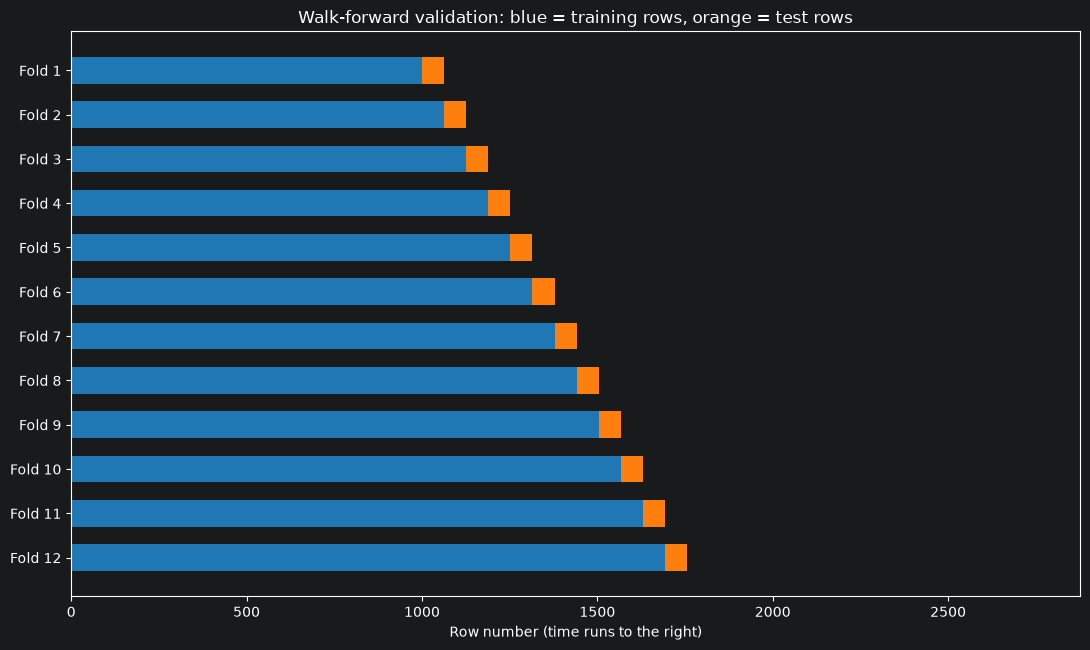

,train_rows,train_from,train_to,test_rows,test_from,test_to
fold,,,,,,
28,2701,2013-04-04,2024-02-16,63,2024-02-19,2024-05-22
29,2764,2013-04-04,2024-05-22,63,2024-05-23,2024-08-20
30,2827,2013-04-04,2024-08-20,49,2024-08-21,2024-10-30


In [23]:
splits = list(walk_forward_splits(len(dataset), config.INITIAL_TRAIN, config.TEST_SIZE))
print("Number of folds:", len(splits))
plot_walk_forward_layout(splits, len(dataset))
describe_splits(splits, dataset.index).tail(3)

### Choose the settings of the models on the first training block only

As in Notebook 4, we choose the strength of the Ridge penalty and the depth and learning rate of the boosting model using only the first training block, so that the test period plays no part in the choice.

In [24]:
tuning_X, tuning_y = X.iloc[: config.INITIAL_TRAIN], y.iloc[: config.INITIAL_TRAIN]
inner_splits = list(walk_forward_splits(len(tuning_X), initial_train=500, test_size=100))

def tuning_score(model_factory):
    predicted = walk_forward_predict(model_factory, tuning_X, tuning_y, inner_splits)
    mask = predicted.notna()
    return float(np.mean((tuning_y[mask] - predicted[mask]) ** 2))

ridge_scores = {alpha: tuning_score(lambda a=alpha: Ridge(alpha=a)) for alpha in [1, 10, 100, 1000, 10000, 100000]}
best_alpha = min(ridge_scores, key=ridge_scores.get)
print(pd.Series(ridge_scores, name="Tuning MSE").to_frame().T.to_string())
print("Chosen Ridge alpha:", best_alpha)


def make_boosting(max_depth=3, learning_rate=0.03, max_iter=200, loss="squared_error", quantile=None):
    return HistGradientBoostingRegressor(
        loss=loss, quantile=quantile, max_depth=max_depth, learning_rate=learning_rate, max_iter=max_iter,
        min_samples_leaf=40, l2_regularization=1.0, random_state=config.SEED)

grid = [(depth, rate) for depth in (2, 3) for rate in (0.01, 0.03)]
boost_scores = {combo: tuning_score(lambda c=combo: make_boosting(max_depth=c[0], learning_rate=c[1])) for combo in grid}
print(pd.Series(boost_scores, name="Tuning MSE").rename_axis(["max_depth", "learning_rate"]).to_frame().round(8).to_string())
best_depth, best_rate = min(boost_scores, key=boost_scores.get)
print("Chosen boosting settings: max_depth =", best_depth, ", learning_rate =", best_rate)

              1         10        100       1000      10000     100000
Tuning MSE  0.000219  0.000218  0.000213  0.000208  0.000214  0.000217
Chosen Ridge alpha: 1000
                         Tuning MSE
max_depth learning_rate            
2         0.01             0.000202
          0.03             0.000204
3         0.01             0.000204
          0.03             0.000207
Chosen boosting settings: max_depth = 2 , learning_rate = 0.01


### The walk-forward test

We fit three models. The first two use all the predictors. The third is a deliberately simple rival that uses **only yesterday's return**. If the simple rival does as well as the complicated models, the extra predictors are not earning their place.

In [25]:
predictions = {}
started = time.time()
predictions["Ridge"] = walk_forward_predict(lambda: Ridge(alpha=best_alpha), X, y, splits)
predictions["Gradient boosting"] = walk_forward_predict(
    lambda: make_boosting(max_depth=best_depth, learning_rate=best_rate), X, y, splits)
# A deliberately simple rival: a straight line through yesterday's return, and nothing else
predictions["Yesterday's return only"] = walk_forward_predict(
    lambda: LinearRegression(), dataset[["ret_lag1"]], y, splits)
print(f"The models finished in {time.time() - started:.0f} seconds")

scores = compare_models(dataset, predictions).rename(columns={"RMSE ($)": "RMSE (KES)", "MAE ($)": "MAE (KES)"})
# The directional accuracy in this table counts a day with no price change as a miss, which is unfair on the NSE.
# We measure it properly in the next cell, on the days when the price did move.
scores.drop(columns="Directional accuracy").round(4)

The models finished in 7 seconds


,RMSE (KES),MAE (KES),MAPE (%),Out-of-sample R2 (returns)
Naive (no change),0.4538,0.3017,1.1681,0.0000
Ridge,0.4464,0.3041,1.1788,0.0314
Gradient boosting,0.4420,0.3014,1.1669,0.0476
Yesterday's return only,0.4464,0.3020,1.1666,0.0391


In [26]:
scored_rows = pd.concat(predictions, axis=1).dropna().index
actual = dataset.loc[scored_rows, "target_return"]
non_zero = (actual != 0).values

rows = []
for name, series in predictions.items():
    forecast = series.loc[scored_rows]
    statistic, p_dm = diebold_mariano(actual, forecast, np.zeros(len(scored_rows)))
    hits = int(np.sum(np.sign(actual[non_zero]) == np.sign(forecast[non_zero])))
    hit_rate = hits / int(non_zero.sum())
    p_hit = stats.binomtest(hits, int(non_zero.sum()), 0.5).pvalue
    rows.append({"Model": name, "DM statistic vs naive": statistic, "DM p-value": p_dm,
                 "Verdict": dm_verdict(statistic, p_dm),
                 "Hit rate (days with a move)": hit_rate, "p-value vs 50%": p_hit})
always_up = float((actual[non_zero] > 0).mean())
print(f"Test days scored: {len(scored_rows)} | days with a non-zero return: {int(non_zero.sum())}")
print(f"The hit rate of the rule 'always predict a rise' on these days: {always_up:.1%}")
pd.DataFrame(rows).set_index("Model").round(4)

Test days scored: 1876 | days with a non-zero return: 1562
The hit rate of the rule 'always predict a rise' on these days: 49.6%


,DM statistic vs naive,DM p-value,Verdict,Hit rate (days with a move),p-value vs 50%
Model,,,,,
Ridge,-2.8121,0.0050,Significantly BETTER than naive,0.5531,0.0
Gradient boosting,-5.7536,0.0000,Significantly BETTER than naive,0.5992,0.0
Yesterday's return only,-2.9168,0.0036,Significantly BETTER than naive,0.5960,0.0


Read the tables in the usual order: first the error compared with the naive row, then the R2, then the Diebold-Mariano test, then the hit rate.

For Safaricom the result is **different from Apple**. Both models that use all the predictors have a smaller error than the naive forecast, the out-of-sample R2 is positive (a few percent), the Diebold-Mariano test says that the difference is bigger than luck, and the hit rate on days with a move is clearly above 50 percent. The rule "always predict a rise", printed under the table, scores about 50 percent because the share price fell in the later years, so the hit rate is not just a reflection of a rising stock. (We measure the hit rate only on days when the price moved. A day with no change has no direction.)

Now look at the third model. The model that uses **only yesterday's return** has a better R2 than Ridge with every predictor, and it is not far behind gradient boosting. That is the real finding. The edge comes from the positive autocorrelation you saw above, and not from the Kenyan economy.

Before you celebrate, ask three questions.

1. **Where does the edge come from?** The ablation in Step 11 answers this.
2. **Would it survive in practice?** A forecast that is right 55 to 60 percent of the time is only useful if you can trade at the price in the data, after paying brokerage, taxes, and the spread between the buying and selling prices. We have not tested this, and Notebook 4 showed how quickly costs can remove a small edge.
3. **Is it a feature of the measurement?** If the *Day Price* is an average and not a true closing trade, part of the "predictability" is a statistical artefact of the averaging.

A result that is much better than you expected is a reason to investigate more carefully, not less.

## Step 11: Which Groups of Predictors Help? (Ablation)

As in Notebook 4, we train Ridge with different subsets of the groups, and compare the out-of-sample R2 against the naive forecast. For each group we show how it performs **alone**, and how the model performs **without** it.

In [27]:
def score_features(feature_list):
    predicted = walk_forward_predict(lambda: Ridge(alpha=best_alpha), dataset[feature_list], y, splits)
    mask = predicted.notna()
    return out_of_sample_r2(y[mask], predicted[mask])

all_r2 = score_features(ALL_FEATURES)
rows = []
for group, names in FEATURE_GROUPS.items():
    others_in_model = [f for f in ALL_FEATURES if f not in names]
    rows.append({"Group": group, "Predictors": len(names),
                 "R2 using ONLY this group": score_features(names),
                 "R2 WITHOUT this group": score_features(others_in_model)})
ablation = pd.DataFrame(rows).set_index("Group")
print(f"R2 with ALL predictors: {all_r2:.5f}")
ablation.round(5)

R2 with ALL predictors: 0.03141


,Predictors,R2 using ONLY this group,R2 WITHOUT this group
Group,,,
own_history,12,0.03371,-0.00027
liquidity,3,-0.00503,0.03339
nse_market,4,0.00160,0.03164
shilling_world,9,0.00241,0.02973
inflation,2,-0.00340,0.03232
calendar,4,-0.00351,0.03280


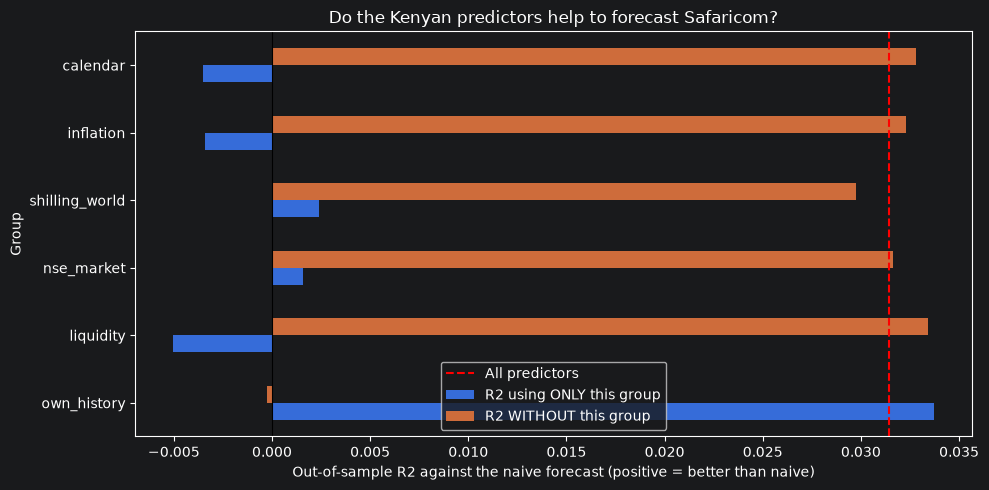

In [28]:
ablation[["R2 using ONLY this group", "R2 WITHOUT this group"]].plot.barh(figsize=(10, 5))
plt.axvline(0, color="black", linewidth=0.8)
plt.axvline(all_r2, color="red", linestyle="--", label="All predictors")
plt.xlabel("Out-of-sample R2 against the naive forecast (positive = better than naive)")
plt.title("Do the Kenyan predictors help to forecast Safaricom?")
plt.legend(); plt.tight_layout(); plt.show()

The chart tells a clear story.

- The **own history** group on its own gives an R2 that is about as high as the model with all the predictors, and removing it takes the R2 down to about zero. All the skill is in the stock's own recent returns, which is mainly yesterday's return.
- The groups that describe the **Kenyan economy** (the banks and other stocks, the shilling and the world, and inflation) have R2 values at or near zero when used alone, and removing any of them changes the result very little.
- Neither the shilling nor inflation helps to forecast the next-day return of Safaricom in this data.

This does not mean that the Kenyan economy does not matter for Safaricom. It means that, at a **one-day** horizon, with a few daily and monthly predictors, and with one model, the effect is too small to detect against the daily noise. Macroeconomic variables work on longer horizons, which is why central banks and analysts forecast inflation and exchange rates over months, not days. Exercise 9 asks you to examine a longer horizon.

## Step 12: Does the Timing Rule Matter?

In Step 8 we chose the safe rule: use foreign information dated before the NSE day. Suppose instead that we forecast in the **evening**, after the US markets have closed. Then the foreign values for day *t* are known, and the "same-day" rule is legitimate. This is a question about **when the forecast is made**, and not a bug.

The table below compares the two rules with Ridge. Which rule you use depends on when your client needs the forecast, and you must state it.

In [29]:
timing_results = {}
for label, same_day in [("Safe rule (forecast at the NSE close)", False), ("Same-day rule (forecast in the evening)", True)]:
    alt_market = build_market_table(same_day=same_day)
    alt_data = make_nse_dataset(alt_market, build_nse_features(alt_market)).dropna()
    alt_splits = list(walk_forward_splits(len(alt_data), config.INITIAL_TRAIN, config.TEST_SIZE))
    predicted = walk_forward_predict(lambda: Ridge(alpha=best_alpha), alt_data[ALL_FEATURES], alt_data["target_return"], alt_splits)
    mask = predicted.notna()
    timing_results[label] = {"Rows scored": int(mask.sum()),
                             "Out-of-sample R2": out_of_sample_r2(alt_data["target_return"][mask], predicted[mask])}
pd.DataFrame(timing_results).T.round(5)

,Rows scored,Out-of-sample R2
Safe rule (forecast at the NSE close),1876.0,0.03141
Same-day rule (forecast in the evening),1876.0,0.03958


The same-day rule gives a slightly higher R2. Information from the US session, which finished after the NSE closed, carries a little more information about the next NSE day. The difference is small, and we have not tested whether it is bigger than luck.

The lesson is about **discipline**, not about the size of the gain. Before you build any model, write down the exact moment at which the forecast is made, and list what is known at that moment. Whether foreign information on the same date is allowed depends on that moment, and an unstated assumption is the most common source of hidden look-ahead bias.

## Step 13: How Uncertain Is the Forecast?

A point forecast hides how unsure we are. As in Notebook 4, we fit gradient boosting models for the 10th and 90th percentiles of the return, so that the range between them should contain the actual return about 80 percent of the time.

In [30]:
started = time.time()
q10 = walk_forward_predict(lambda: make_boosting(loss="quantile", quantile=0.10), X, y, splits)
q90 = walk_forward_predict(lambda: make_boosting(loss="quantile", quantile=0.90), X, y, splits)
print(f"Quantile models finished in {time.time() - started:.0f} seconds")

inside = ((y >= q10) & (y <= q90))[q10.notna()]
print(f"Share of days on which the actual return fell inside the 10% to 90% range: {inside.mean():.1%}  (target: 80%)")
width = (np.exp(q90) - np.exp(q10))[q10.notna()]
print(f"Average width of the range: {width.mean():.1%} of the price")

Quantile models finished in 27 seconds
Share of days on which the actual return fell inside the 10% to 90% range: 73.5%  (target: 80%)
Average width of the range: 3.2% of the price


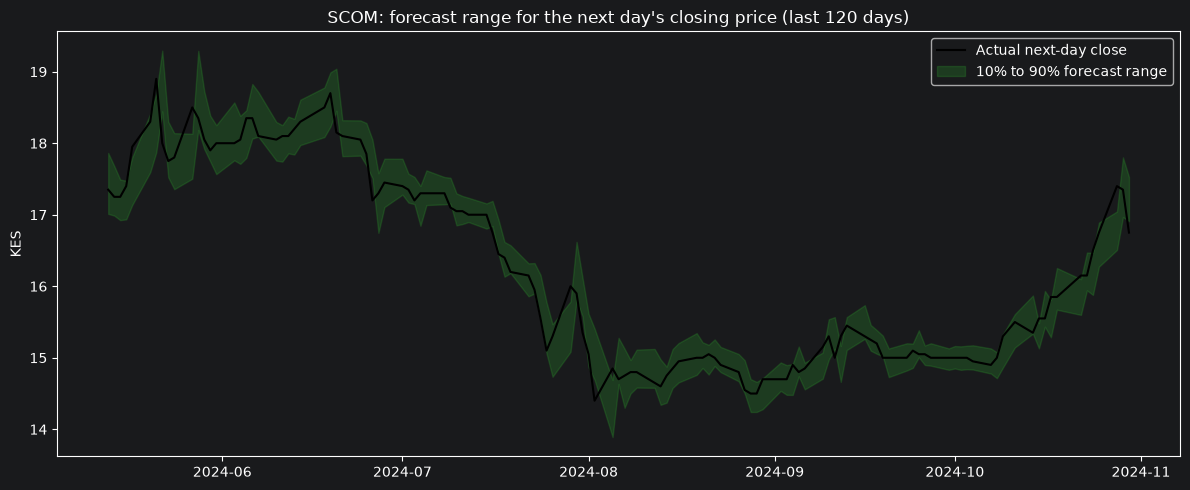

In [31]:
recent = dataset.loc[scored_rows].iloc[-120:]
lower_price = recent["close"] * np.exp(q10.loc[recent.index])
upper_price = recent["close"] * np.exp(q90.loc[recent.index])
plt.figure(figsize=(12, 5))
plt.plot(recent.index, recent["target_close"], color="black", label="Actual next-day close")
plt.fill_between(recent.index, lower_price, upper_price, color="tab:green", alpha=0.25, label="10% to 90% forecast range")
plt.title(f"{TARGET}: forecast range for the next day's closing price (last 120 days)")
plt.ylabel("KES"); plt.legend(); plt.tight_layout(); plt.show()

Compare the share of days inside the range with the 80 percent target. In this run it is about 74 percent, so the range is **too narrow**, and the model is overconfident, as in Notebook 4. A common reason is volatility clustering (Notebook 2): ranges fitted in calm periods are too tight for stormy ones.

Notice also how wide the range is compared with the size of the typical move. A portfolio manager who sees the range learns something that the single number hides: on a typical day, the uncertainty is larger than any edge the model has found.

## Step 14: The Same Stock in Two Currencies

A foreign investor who holds Safaricom earns shillings and spends dollars. The same series, converted to dollars, tells a different story whenever the shilling moves. We divide the price by the exchange rate, using the shilling rate known on the same day.

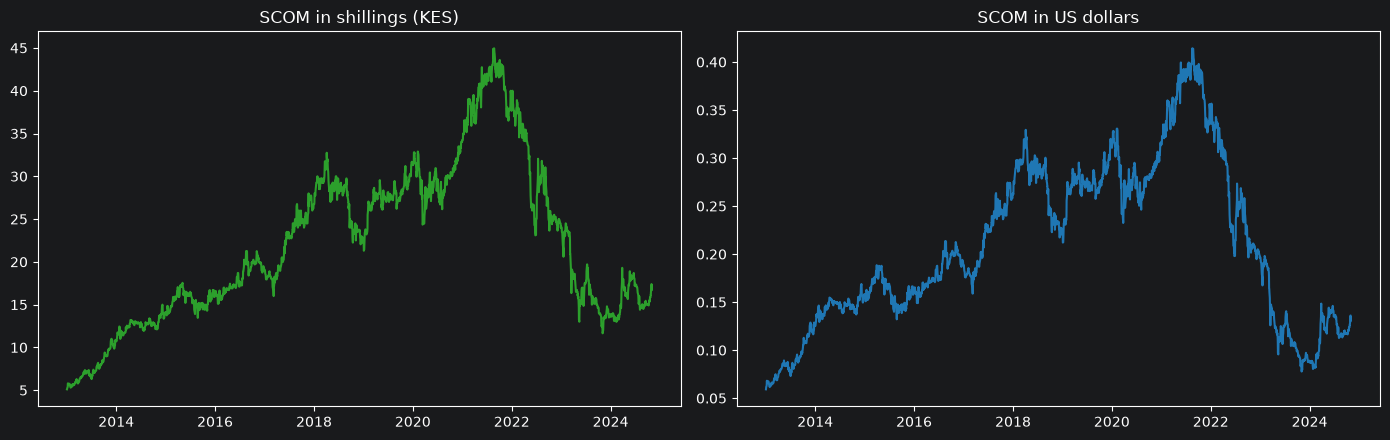

2013 to 2021: change in KES +644% | change in USD +472%
2022 to October 2024: change in KES -56% | change in USD -62%


In [32]:
fx_same_day = align_to_nse(foreign["USDKES"], frame.index, same_day=True)["value"]
price_usd = frame["close"] / fx_same_day

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(frame["close"], color="tab:green"); axes[0].set_title(f"{TARGET} in shillings (KES)")
axes[1].plot(price_usd, color="tab:blue"); axes[1].set_title(f"{TARGET} in US dollars")
plt.tight_layout(); plt.show()

for label, start, end in [("2013 to 2021", "2013-01-01", "2021-12-31"), ("2022 to October 2024", "2022-01-01", "2024-10-31")]:
    kes = frame["close"].loc[start:end]; usd = price_usd.loc[start:end]
    print(f"{label}: change in KES {kes.iloc[-1] / kes.iloc[0] - 1:+.0%} | change in USD {usd.iloc[-1] / usd.iloc[0] - 1:+.0%}")

The shilling lost value against the dollar during the later part of the sample, so for a foreign investor the fall of the share price was **larger** than the fall that Kenyan investors saw. In the earlier part of the sample the gain in dollars was smaller than the gain in shillings, for the same reason. The exchange rate is therefore not only a predictor in a model. It also decides which return a given investor earned.

If your client earns dollars, you should forecast in dollars. Exercise 10 asks you to try.

## Step 15: Limits of This Analysis

Read these limits before you quote any result from this notebook.

1. **The data end in October 2024.** The forecasts are tested on past days, and no forecast is made for the future. To work with later dates you must extend the data yourself.
2. **The prices are not adjusted** for dividends, splits, or bonus issues. We removed moves above 25 percent as probable corporate actions, but smaller adjustments remain in the data.
3. **The files were collected by a researcher** from a website, and have not been checked against the exchange's own records.
4. **The shilling series from Yahoo Finance is an indicative market rate**, not the official rate of the Central Bank of Kenya. The two can differ, particularly in periods of stress.
5. **Inflation is the revised figure** that the World Bank holds today. A forecaster in real time would have used the first release, which may differ. Economists call this the problem of **data vintages**.
6. **One stock, one period.** Results for Safaricom say nothing certain about other shares, and results for 2013 to 2024 say nothing certain about the future.

## Step 16: Exercises

1. Write two sentences that a Kenyan fund manager could understand, about whether your best model beats the naive forecast for Safaricom. Include the Diebold-Mariano p-value.
2. Change `TARGET` to `"KCB"`, then to `"EQTY"`, and run the notebook again. Which results change, and why? (The code removes the target from the bank average automatically.)
3. Change `TARGET` to a stock with a low share of days traded (see Step 4). What happens to the share of zero returns and to the quality of the forecasts? What does this tell you about forecasting thinly traded shares?
4. Test the claim that thin trading creates a **lead-lag** effect. Does yesterday's return of the other NSE stocks (`others_ret_1d` shifted by one day) help to forecast Safaricom? Write the check as a few lines of code, using the walk-forward protocol.
5. In Step 8, change the inflation rule so that a month's figure is used only from the first day of month m + 2. Does the result change? What does this tell you about how sensitive the model is to the exact release date?
6. Visit the Central Bank of Kenya website and find the daily mean exchange rate. Compare it with the Yahoo Finance series for ten dates. How large are the differences?
7. The Central Bank Rate changes only a few times a year. Collect the dates and values from the Central Bank of Kenya, build a predictor that uses each value only from the day after the announcement, and test whether it adds anything.
8. Extend the data: download the daily NSE price list for a few weeks after October 2024 from the NSE website, append the rows to your table, and check that your cleaning code handles the new format.
9. Change the target to the return over the **next 21 trading days** (see Notebook 7 for how to build it and how to use the `gap`). Do the shilling and inflation predictors become more useful at a longer horizon?
10. Repeat the analysis with the **USD price** of Safaricom (Step 14) as the target. Do the conclusions about the usefulness of the predictors change?
11. Compare the *Day Price* for ten dates with the closing prices in the NSE's own daily price lists. Is the *Day Price* the last trade of the day? Does the positive autocorrelation survive if you use the official closing price?
12. Suppose the positive autocorrelation is real. List the costs and frictions that would reduce what a trader could earn from it, and estimate whether a hit rate of 55 percent would survive them.

## Summary

- Free data exist for the Nairobi Securities Exchange and for the Kenyan economy, but they must be **downloaded carefully, verified, and cleaned**. Six different problems appeared in the NSE files alone.
- **Thin trading** and **stale prices** mean that a return of zero often means "no trade". Choose a stock that trades often enough to forecast.
- Data that arrive at different times must be aligned with the **moment of the forecast** in mind. A foreign price dated the same day, or an inflation figure that was not yet published, is a form of look-ahead bias.
- The method is the same as for Apple: forecast returns, test on days the model has not seen, compare with the naive forecast, and test whether a difference is bigger than luck.
- In this data, the forecasts beat the naive forecast, but almost all of the skill comes from **yesterday's return**, and the predictors that describe the Kenyan economy add nothing measurable at a one-day horizon. A result that is better than expected needs an explanation before it is reported, and the explanation may be about how the data were measured.

### Data sources

- Wanjawa, B. *Nairobi Securities Exchange (NSE) All Stocks Prices*, 2013 to 2020 ([doi:10.17632/73rb78pmzw.2](https://doi.org/10.17632/73rb78pmzw.2)), 2021 ([doi:10.17632/97hkwn5y3x.4](https://doi.org/10.17632/97hkwn5y3x.4)), 2022 ([doi:10.17632/jmcdmnyh2s.2](https://doi.org/10.17632/jmcdmnyh2s.2)), and 2023 to 2024 ([doi:10.17632/ss5pfw8xnk.1](https://doi.org/10.17632/ss5pfw8xnk.1)). Mendeley Data.
- World Bank. *Global Economic Monitor*, consumer price index for Kenya.
- Yahoo Finance, accessed through the `yfinance` package.